# Colombia: inflation, the peso and the reaction of Banco de la República

**Objective:** analyse the inflation of Colombia against the target of 3% +/- 1, estimate how Banco de la República reacts to inflation (Taylor rule), measure how much of a depreciation of the peso goes to consumer prices (pass-through) and forecast inflation for the next 12 months with a SARIMA model.

**Data:**
- CPI of Colombia (source DANE) from the OECD SDMX API
- Policy rate of Banco de la República from the BIS (central bank policy rates)
- TRM exchange rate from the Superintendencia Financiera (datos.gov.co, dataset `32sa-8pi3`)

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `requests` and `statsmodels`.

## Part 1. Libraries and data

In [1]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

In [2]:
def oecd(transformacion, medida):
    url = ("https://sdmx.oecd.org/public/rest/data/OECD.SDD.TPS,DSD_PRICES@DF_PRICES_ALL,1.0/"
           f"COL.M.N.CPI.{medida}._T.N.{transformacion}?format=csv&startPeriod=1995-01")
    d = pd.read_csv(io.StringIO(requests.get(url, timeout=120).text))
    return d.set_index(pd.PeriodIndex(d["TIME_PERIOD"], freq="M"))["OBS_VALUE"].sort_index()

inflacion = oecd("GY", "PA")          # annual growth rate
ipc = oecd("_Z", "IX")                # index

bis = pd.read_csv(io.StringIO(requests.get("https://stats.bis.org/api/v2/data/dataflow/BIS/WS_CBPOL/1.0/M.CO?format=csv", timeout=120).text))
tasa = bis.set_index(pd.PeriodIndex(bis["TIME_PERIOD"], freq="M"))["OBS_VALUE"].sort_index()

trm = pd.DataFrame(requests.get("https://www.datos.gov.co/resource/32sa-8pi3.json",
                                params={"$select": "valor, vigenciadesde", "$limit": 50000, "$order": "vigenciadesde"}, timeout=120).json())
trm["fecha"] = pd.to_datetime(trm["vigenciadesde"])
trm = trm.set_index("fecha")["valor"].astype(float).resample("ME").mean()
trm.index = trm.index.to_period("M")

df = pd.DataFrame({"inflation": inflacion, "cpi": ipc, "policy_rate": tasa, "trm": trm}).loc["2000-01":]
df.to_csv("data/colombia_monthly.csv")
df.dropna().tail()

,inflation,cpi,policy_rate,trm
2026-05,5.842079,185.7352,11.25,3718.855263
2026-06,6.142751,186.4550,11.25,3497.091176
2026-07,6.026292,186.7650,12.00,3272.010000
2026-08,6.241686,187.4956,12.00,3126.775789
2026-09,6.289791,188.1801,12.00,3184.330952


## Part 2. Inflation and the policy rate

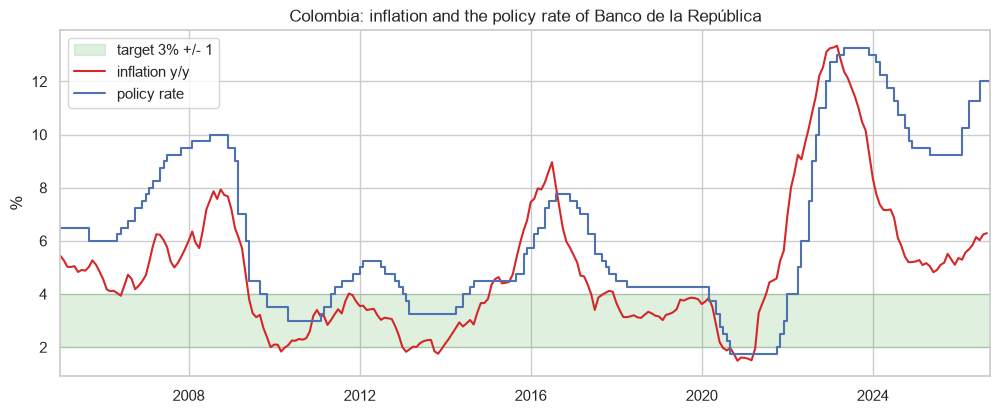

Peak of inflation: 2023-03 13.34
Peak of the rate since 2010: 2023-05 13.25
Latest: 2026-09 6.29 % inflation | 12.0 % rate
2025-10     9.25
2025-11     9.25
2025-12     9.25
2026-01     9.25
2026-02    10.25
2026-03    10.25
2026-04    11.25
2026-05    11.25
2026-06    11.25
2026-07    12.00
2026-08    12.00
2026-09    12.00
2026-10      NaN
Freq: M


In [3]:
x = df.index.to_timestamp()
plt.figure(figsize=(12, 4.5))
plt.fill_between(x, 2, 4, color="tab:green", alpha=0.15, label="target 3% +/- 1")
plt.plot(x, df["inflation"], color="tab:red", label="inflation y/y")
plt.step(x, df["policy_rate"], where="post", label="policy rate")
plt.xlim(pd.Timestamp("2005-01-01"), x.max())
plt.title("Colombia: inflation and the policy rate of Banco de la República")
plt.ylabel("%")
plt.legend()
plt.savefig("figures/inflation_and_rate.png", bbox_inches="tight")
plt.show()
print("Peak of inflation:", df["inflation"].idxmax(), round(df["inflation"].max(), 2))
print("Peak of the rate since 2010:", df.loc["2010":, "policy_rate"].idxmax(), df.loc["2010":, "policy_rate"].max())
print("Latest:", df["inflation"].dropna().index[-1], round(df["inflation"].dropna().iloc[-1], 2), "% inflation |", df["policy_rate"].dropna().iloc[-1], "% rate")
print(df.loc["2025-10":, "policy_rate"].to_string())

Inflation reached 13.3% in March 2023 and the bank took the rate to 13.25%. After a period of cuts, inflation went up again in 2026 (above 6%) and the bank raised the rate from 9.25% to 12%.

## Part 3. Taylor rule with smoothing

Central banks move the rate gradually, so we estimate: i(t) = c + rho i(t-1) + b pi(t) + d (pi(t) - pi(t-12)). The long-run response to inflation is b / (1 - rho). The Taylor principle says it should be bigger than 1 (the real rate goes up when inflation goes up).

In [4]:
t = df[["policy_rate", "inflation"]].dropna().loc["2005-01":].copy()
t["rate_lag"] = t["policy_rate"].shift(1)
t["d_infl"] = t["inflation"] - t["inflation"].shift(12)
t = t.dropna()
m = sm.OLS(t["policy_rate"], sm.add_constant(t[["rate_lag", "inflation", "d_infl"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
print(m.summary().tables[1])
rho = m.params["rate_lag"]
largo = m.params["inflation"] / (1 - rho)
# standard error with the delta method
grad = np.array([0, m.params["inflation"] / (1 - rho) ** 2, 1 / (1 - rho), 0])
se = np.sqrt(grad @ m.cov_params().values @ grad)
print("rho:", round(rho, 3), "| long-run response to inflation:", round(largo, 2), "| se:", round(se, 2))

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0028      0.038      0.073      0.942      -0.072       0.078
rate_lag       0.9848      0.021     46.319      0.000       0.943       1.026
inflation      0.0233      0.027      0.872      0.383      -0.029       0.076
d_infl         0.0613      0.012      4.977      0.000       0.037       0.085
rho: 0.985 | long-run response to inflation: 1.53 | se: 0.73


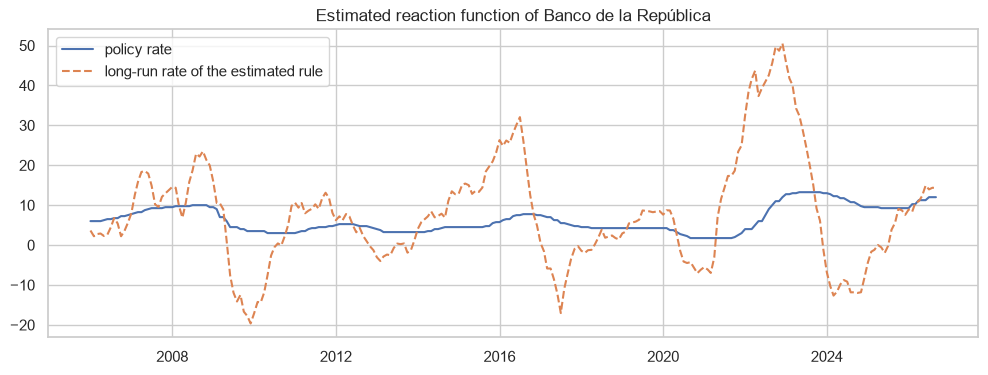

In [5]:
t["rule"] = (m.params["const"] + m.params["inflation"] * t["inflation"] + m.params["d_infl"] * t["d_infl"]) / (1 - rho)
plt.figure(figsize=(12, 4))
plt.plot(t.index.to_timestamp(), t["policy_rate"], label="policy rate")
plt.plot(t.index.to_timestamp(), t["rule"], ls="--", label="long-run rate of the estimated rule")
plt.title("Estimated reaction function of Banco de la República")
plt.legend()
plt.savefig("figures/taylor_rule.png", bbox_inches="tight")
plt.show()

The point estimate (1.53) respects the Taylor principle, but with a lot of uncertainty because rho is very close to 1: the bank moves the rate very slowly.

## Part 4. Exchange rate pass-through

Monthly inflation against the depreciation of the peso of this month and of the 12 months before, with month dummies (in Colombia many prices are adjusted in January).

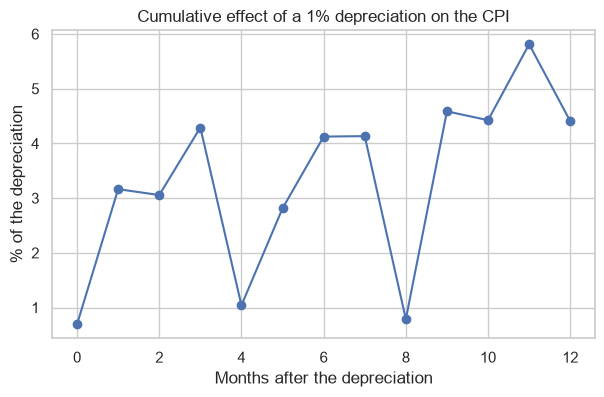

Pass-through: impact 0.7 % | 6 months 4.1 % | 12 months 4.4 %


In [6]:
p = pd.DataFrame({"dp": 100 * np.log(df["cpi"]).diff(), "de": 100 * np.log(df["trm"]).diff()}).dropna().loc["2005-01":]
for k in range(1, 13):
    p[f"de_{k}"] = p["de"].shift(k)
p["dp_1"] = p["dp"].shift(1)
for mes in range(1, 12):
    p[f"m{mes}"] = (p.index.month == mes).astype(int)
p = p.dropna()
xs = ["de"] + [f"de_{k}" for k in range(1, 13)] + ["dp_1"] + [f"m{mes}" for mes in range(1, 12)]
pt = sm.OLS(p["dp"], sm.add_constant(p[xs])).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
acum = pt.params[["de"] + [f"de_{k}" for k in range(1, 13)]].cumsum() / (1 - pt.params["dp_1"])

plt.figure(figsize=(7, 4))
plt.plot(range(13), acum.values * 100, marker="o")
plt.title("Cumulative effect of a 1% depreciation on the CPI")
plt.xlabel("Months after the depreciation")
plt.ylabel("% of the depreciation")
plt.savefig("figures/pass_through.png", bbox_inches="tight")
plt.show()
print("Pass-through: impact", round(acum.iloc[0] * 100, 1), "% | 6 months", round(acum.iloc[6] * 100, 1), "% | 12 months", round(acum.iloc[12] * 100, 1), "%")

The pass-through is low: after one year only around 4% of a depreciation reaches the consumer prices.

## Part 5. SARIMA forecast

We choose the order with the AIC between some candidates and we check the model with a backtest: every 6 months since 2015 we forecast 12 months ahead and compare with a random walk (inflation stays the same).

In [7]:
y = df["inflation"].dropna().loc["2005-01":]
mejor = None
for orden in [(1, 1, 0), (2, 1, 0), (1, 1, 1), (2, 1, 1)]:
    for est in [(0, 0, 1, 12), (1, 0, 1, 12)]:
        modelo = SARIMAX(y, order=orden, seasonal_order=est).fit(disp=False)
        if mejor is None or modelo.aic < mejor[0].aic:
            mejor = (modelo, orden, est)
modelo, orden, est = mejor
print("Best model: SARIMA", orden, est, "| AIC:", round(modelo.aic, 1))

errores, rw = [], []
for origen in y.loc["2015-01":y.index[-13]].index[::6]:
    tr = y.loc[:origen]
    f = SARIMAX(tr, order=orden, seasonal_order=est).fit(disp=False).forecast(12).iloc[-1]
    errores.append(f - y.loc[origen + 12])
    rw.append(tr.iloc[-1] - y.loc[origen + 12])
print("RMSE 12 months ahead, SARIMA:", round(np.sqrt(np.mean(np.square(errores))), 2), "| random walk:", round(np.sqrt(np.mean(np.square(rw))), 2))

Best model: SARIMA (2, 1, 1) (0, 0, 1, 12) | AIC: -27.7


RMSE 12 months ahead, SARIMA: 3.12 | random walk: 3.42


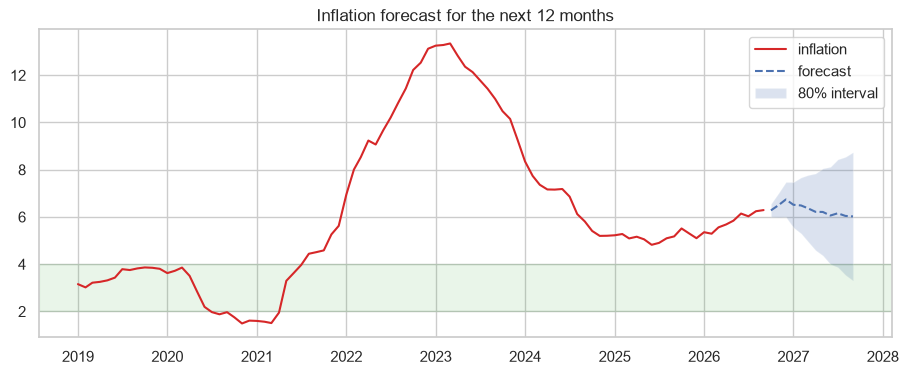

Forecast for 2027-09 : 6.02 % | 80% interval: [3.31 8.74]
Ex-ante real rate: 5.98 %


In [8]:
fc = modelo.get_forecast(12)
ic = fc.conf_int(alpha=0.2)
plt.figure(figsize=(11, 4))
plt.plot(y.loc["2019":].index.to_timestamp(), y.loc["2019":], color="tab:red", label="inflation")
plt.plot(fc.predicted_mean.index.to_timestamp(), fc.predicted_mean, ls="--", label="forecast")
plt.fill_between(ic.index.to_timestamp(), ic.iloc[:, 0], ic.iloc[:, 1], alpha=0.2, label="80% interval")
plt.axhspan(2, 4, color="tab:green", alpha=0.1)
plt.title("Inflation forecast for the next 12 months")
plt.legend()
plt.savefig("figures/inflation_forecast.png", bbox_inches="tight")
plt.show()
print("Forecast for", fc.predicted_mean.index[-1], ":", round(fc.predicted_mean.iloc[-1], 2), "% | 80% interval:", np.round(ic.iloc[-1].values, 2))
print("Ex-ante real rate:", round(df["policy_rate"].dropna().iloc[-1] - fc.predicted_mean.iloc[-1], 2), "%")

## Conclusions

- Inflation in Colombia is again far from the target (above 6% in 2026) and the bank is raising the rate.
- The estimated reaction function respects the Taylor principle, with a very slow adjustment of the rate.
- The pass-through of the peso to consumer prices is low, around 4% after one year.
- The SARIMA model expects inflation around 6% in 12 months, but with a wide interval: forecasting inflation one year ahead is difficult, and the model is only a little better than a random walk.